In [3]:
from data_process import *
from mcar.simulate import *
from graphOUedge import GraphOUEdge

def pred_robust(seed: int, p: float, gamma: float, num_node: int, scale: float, T: int, dir: str, forecast_step: int):
    TICKERS = [str(i) for i in range (num_node)]
    G = nx.erdos_renyi_graph(num_node, p, seed=seed)
    G = nx.relabel_nodes(G, dict(enumerate(TICKERS)))
    A = nx.to_numpy_array(G)

    adj_sim = adj_to_line_graph(A, TICKERS)
    adj_L_sim = adjacency_matrices(adj_sim[0], 1)
    W_C_sim = edge_weight(adj_L_sim)
    X_sim = GraphOUEdge([1], len(adj_sim[1]), 1, adj_L_sim, W_C_sim, gamma, dir, scale=scale, T=T)
    X_sim.alpha_set(np.array([[5]+[1 for _ in range(len(adj_sim[1]) - 1)]]))
    X_sim.beta_set([[2]])
    X_sim.Q_matrix()
    data_sim = X_sim.simulate('CP', 1000, seed=1000, rate=1)

    edges = list(G.edges())
    G_without_first = G.copy()
    first_edge = edges[0]
    G_without_first.remove_edge(*first_edge)
    A_without_first = nx.to_numpy_array(G_without_first, nodelist=TICKERS)

    G_without_last = G.copy()
    last_edge = edges[-1]
    G_without_last.remove_edge(*last_edge)
    A_without_last = nx.to_numpy_array(G_without_last, nodelist=TICKERS)

    model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=T**4, gamma=gamma, label='correct', scenario=dir)
    model_pred(data=data_sim, test_size=400, adj_sim=adj_to_line_graph(A_without_first, TICKERS), forecast_step=forecast_step, P_Q_ratio=T**4, gamma=gamma, label='missing_5', scenario=dir)
    model_pred(data=data_sim, test_size=400, adj_sim=adj_to_line_graph(A_without_last, TICKERS), forecast_step=forecast_step, P_Q_ratio=T**4, gamma=gamma, label='missing_1', scenario=dir)

    boxplot_(data_sim, dir)

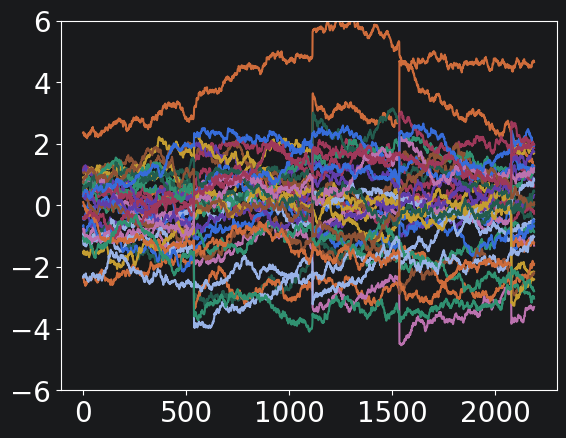

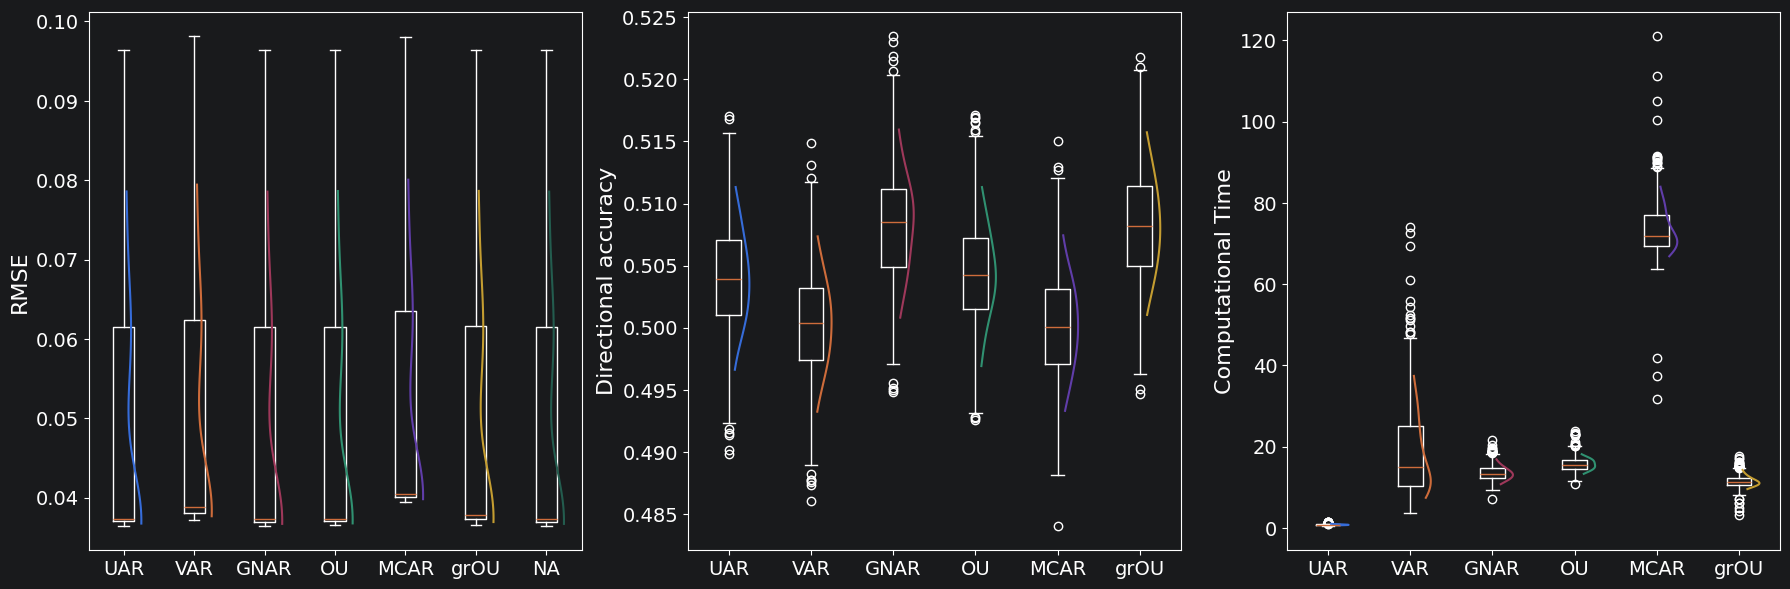

correct
                                UAR        VAR       GNAR         OU  \
RMSE_mean                  0.048903   0.050031   0.048868   0.048931   
RMSE_std                   0.015946   0.015883   0.015948   0.015941   
Directional_accuracy_mean  0.504013   0.500323   0.508226   0.504321   
Directional_accuracy_std   0.004491   0.004332   0.004614   0.004341   
Computational_time_mean    0.772306  18.280053  13.456439  15.681419   
Computational_time_std     0.126270  10.299596   1.894042   1.632749   

                                MCAR       grOU        NA  
RMSE_mean                   0.051536   0.049181  0.048868  
RMSE_std                    0.015331   0.015885  0.015948  
Directional_accuracy_mean   0.500119   0.508277       NaN  
Directional_accuracy_std    0.004322   0.004510       NaN  
Computational_time_mean    73.401853  11.433779       NaN  
Computational_time_std      6.161526   1.496288       NaN  


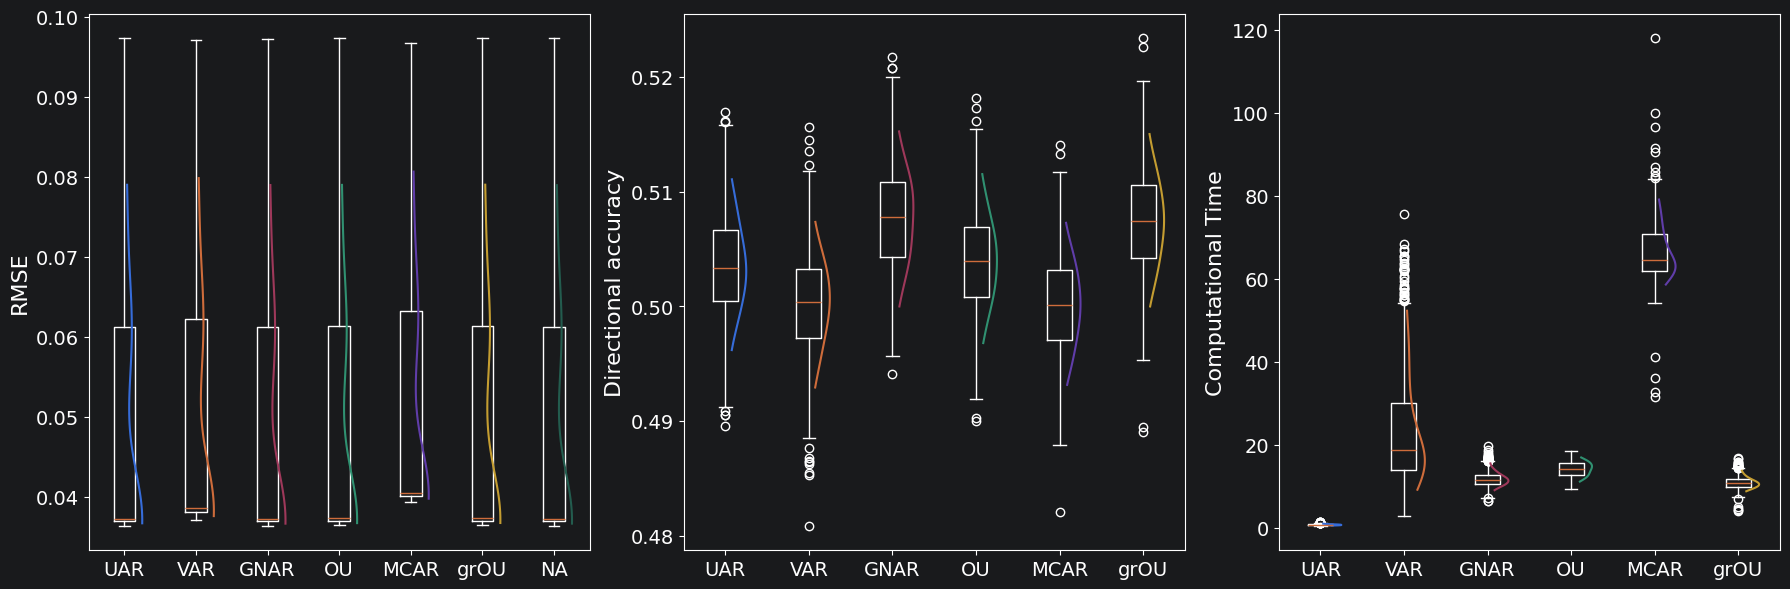

missing_5
                                UAR        VAR       GNAR         OU  \
RMSE_mean                  0.048884   0.049974   0.048849   0.048913   
RMSE_std                   0.015925   0.015858   0.015927   0.015921   
Directional_accuracy_mean  0.503541   0.500273   0.507695   0.503998   
Directional_accuracy_std   0.004541   0.004481   0.004594   0.004474   
Computational_time_mean    0.710529  23.637283  11.754323  14.152254   
Computational_time_std     0.143327  13.628886   1.879082   1.840352   

                                MCAR       grOU        NA  
RMSE_mean                   0.051522   0.048935  0.048847  
RMSE_std                    0.015312   0.015912  0.015927  
Directional_accuracy_mean   0.500132   0.507341       NaN  
Directional_accuracy_std    0.004367   0.004556       NaN  
Computational_time_mean    66.647161  10.852896       NaN  
Computational_time_std      6.948903   1.518740       NaN  


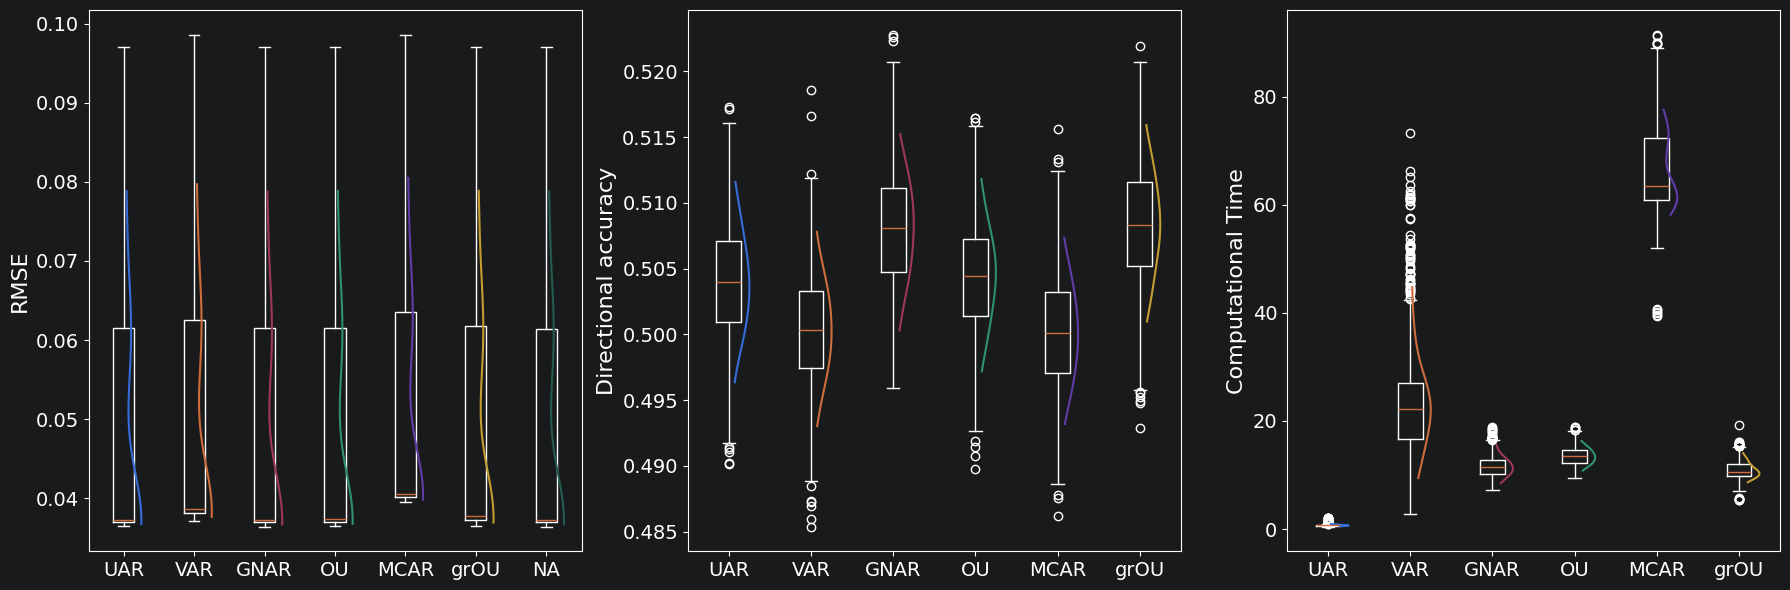

missing_1
                                UAR        VAR       GNAR         OU  \
RMSE_mean                  0.048932   0.050027   0.048899   0.048960   
RMSE_std                   0.015977   0.015919   0.015979   0.015973   
Directional_accuracy_mean  0.503990   0.500347   0.507948   0.504418   
Directional_accuracy_std   0.004574   0.004485   0.004616   0.004452   
Computational_time_mean    0.690216  23.339855  11.595704  13.509373   
Computational_time_std     0.184305  10.641853   2.076385   1.704388   

                                MCAR       grOU        NA  
RMSE_mean                   0.051569   0.049222  0.048897  
RMSE_std                    0.015365   0.015913  0.015980  
Directional_accuracy_mean   0.500158   0.508348       NaN  
Directional_accuracy_std    0.004390   0.004687       NaN  
Computational_time_mean    66.157600  10.916065       NaN  
Computational_time_std      7.105615   1.700414       NaN  


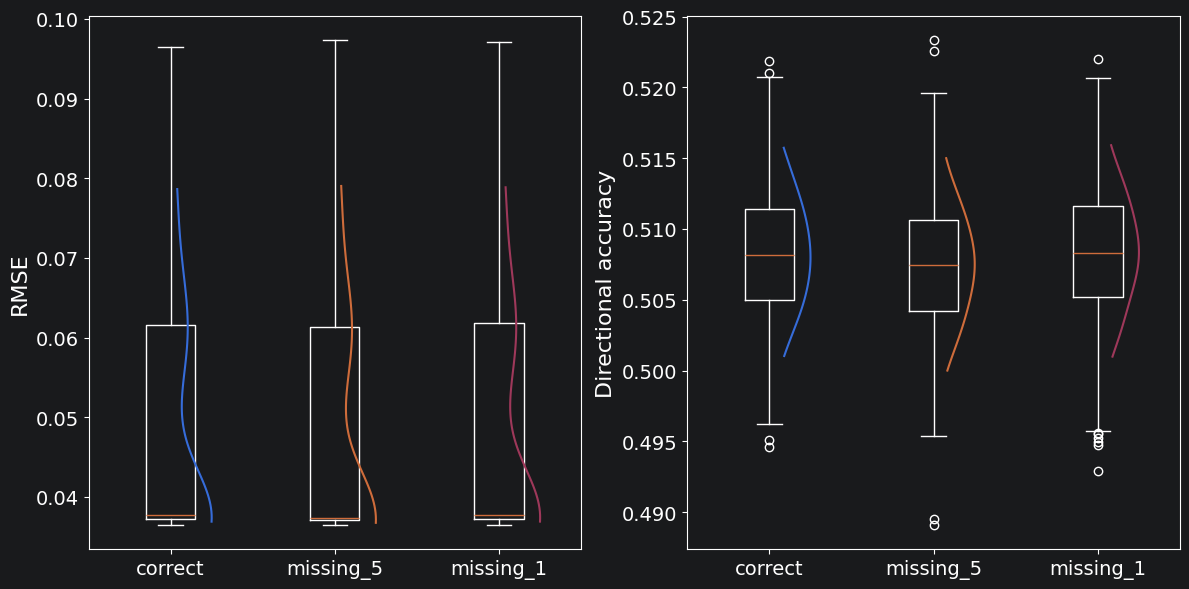

In [4]:
pred_robust(123, 0.15, 1.01, 20, 1, 3, 'test', 1)